In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skewnorm

## The Hit-or-miss method

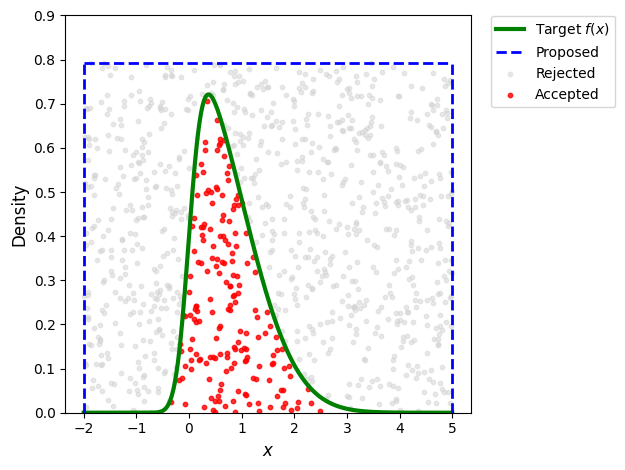

In [2]:

dist_target = skewnorm(a=5, loc=0, scale=1)

# Range for the uniform "box"
x_min, x_max = -2, 5
# Find the peak of the PDF to set the height of the uniform box
x_fine = np.linspace(x_min, x_max, 1000)
y_max = dist_target.pdf(x_fine).max() * 1.1 # Adding 10% buffer

# Generate random points for the Accept-Reject method
num_samples = 1000
x_samples = np.random.uniform(x_min, x_max, num_samples)
y_samples = np.random.uniform(0, y_max, num_samples)

# Acceptance logic: Point is accepted if y <= f(x)
pdf_values = dist_target.pdf(x_samples)
accepted = y_samples <= pdf_values

# Separate points
x_acc, y_acc = x_samples[accepted], y_samples[accepted]
x_rej, y_rej = x_samples[~accepted], y_samples[~accepted]

# 1. Plot the Target PDF
plt.plot(x_fine, dist_target.pdf(x_fine), 'g-', lw=3, label='Target $f(x)$')

# 2. Plot the Proposal (Uniform "Box")
plt.hlines(y_max, x_min, x_max, colors='blue', linestyles='--', lw=2, label=r'Proposed')
plt.vlines([x_min, x_max], 0, y_max, colors='blue', linestyles='--', lw=2)

# 3. Scatter the points
plt.scatter(x_rej, y_rej, color='lightgray', s=10, alpha=0.5, label='Rejected')
plt.scatter(x_acc, y_acc, color='red', s=10, alpha=0.8, label='Accepted')

# Formatting
plt.xlabel('$x$', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.ylim(0, 0.9)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.show()
#@title { vertical-output: true}

## The rejection method

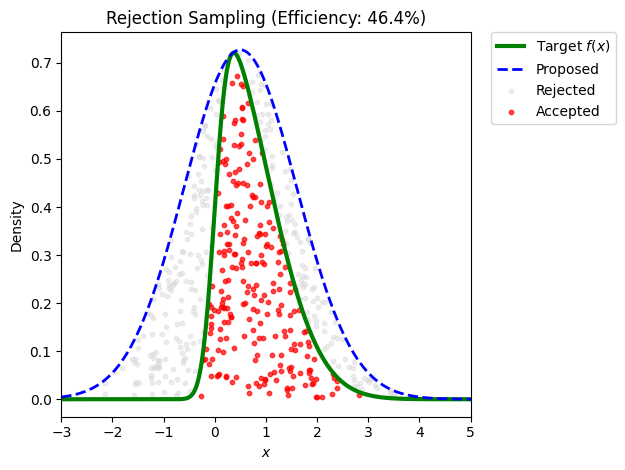

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skewnorm, norm

# 1. Setup Distributions
dist_target = skewnorm(a=5, loc=0, scale=1)
dist_proposal = norm(loc=0.5, scale=1.1)  # Gaussian proposal with wider spread

# 2. Find the scaling constant M
# We need M such that M * g(x) >= f(x).
# A simple way is to find the max of f(x)/g(x)
x_fine = np.linspace(-3, 6, 1000)
M = np.max(dist_target.pdf(x_fine) / dist_proposal.pdf(x_fine))

# 3. Generate Samples
num_samples = 500
# Step A: Sample x from the proposal distribution g(x)
x_samples = dist_proposal.rvs(num_samples)

# Step B: Sample y uniformly up to the proposal envelope M * g(x)
y_samples = np.random.uniform(0, M * dist_proposal.pdf(x_samples), num_samples)

# 4. Acceptance Logic
pdf_target_values = dist_target.pdf(x_samples)
accepted = y_samples <= pdf_target_values

x_acc, y_acc = x_samples[accepted], y_samples[accepted]
x_rej, y_rej = x_samples[~accepted], y_samples[~accepted]

# 5. Visualization
#plt.figure(figsize=(10, 6))

# Plot Target and Envelope
plt.plot(x_fine, dist_target.pdf(x_fine), 'g-', lw=3, label='Target $f(x)$')
plt.plot(x_fine, M * dist_proposal.pdf(x_fine), 'b--', lw=2, label='Proposed')

# Scatter the points
plt.scatter(x_rej, y_rej, color='lightgray', s=10, alpha=0.4, label='Rejected')
plt.scatter(x_acc, y_acc, color='red', s=10, alpha=0.7, label='Accepted')

plt.title(f'Rejection Sampling (Efficiency: {100*sum(accepted)/num_samples:.1f}%)')
plt.xlabel('$x$')
plt.ylabel('Density')
plt.legend()
plt.xlim(-3, 5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()

plt.show()
#@title { vertical-output: true}

## The transformation method

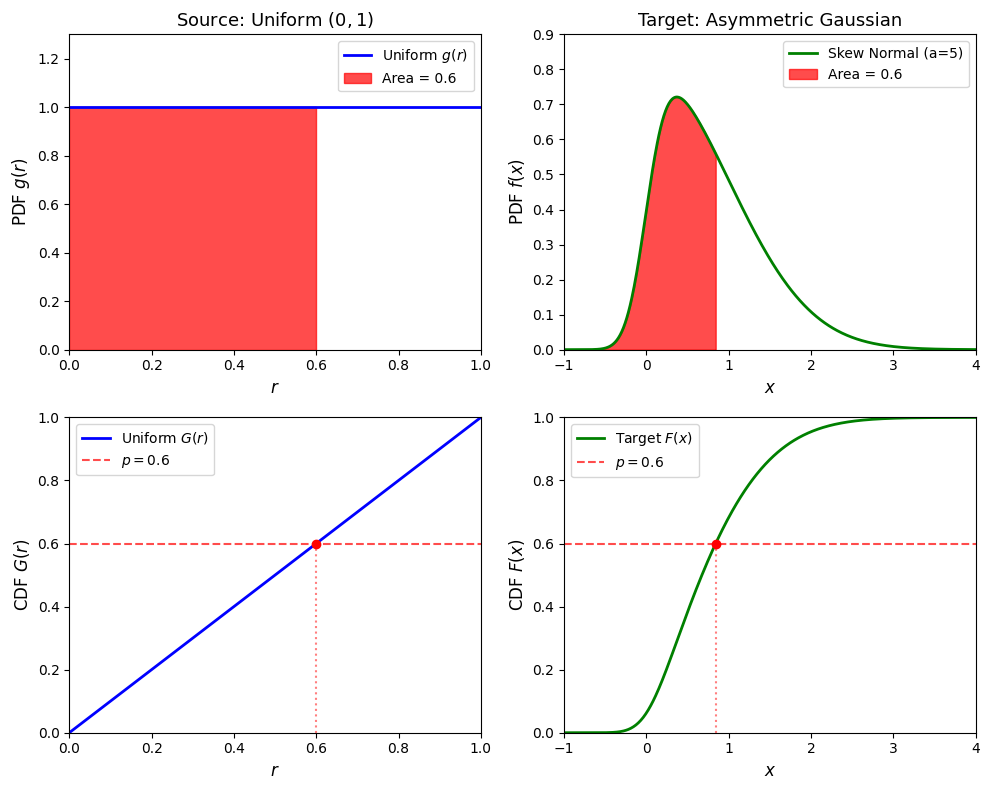

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform, skewnorm

# Set style
plt.style.use('default')

# Set up the figure (2 rows, 2 columns)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Define Distributions
dist_unif = uniform(0, 1)

# Target: Skew Normal distribution
# a=5 (skewness), loc=0 (mean-ish), scale=1 (width)
alpha = 5
dist_target = skewnorm(a=alpha, loc=0, scale=1)

# Define ranges for plotting
r_vals = np.linspace(0, 1, 500)
x_vals = np.linspace(-1, 4, 500) # Adjusted for the right-leaning skew

# Set percentile (60%) to show the mapping in the "skewed" part
p = 0.6
r_p = dist_unif.ppf(p)
x_p = dist_target.ppf(p)

# --- Plot 1: Uniform PDF g(r) ---
axes[0, 0].plot(r_vals, dist_unif.pdf(r_vals), 'b-', lw=2, label='Uniform $g(r)$')
r_fill = np.linspace(0, r_p, 100)
axes[0, 0].fill_between(r_fill, dist_unif.pdf(r_fill), alpha=0.7, color='red', label=f'Area = {p}')
axes[0, 0].set_xlabel('$r$', fontsize=12)
axes[0, 0].set_ylabel('PDF $g(r)$', fontsize=12)
axes[0, 0].set_ylim(0, 1.3)
axes[0, 0].set_xlim(0, 1)
axes[0, 0].set_title('Source: Uniform $(0,1)$', fontsize=13)
axes[0, 0].legend(loc='upper right')

# --- Plot 2: Target PDF f(x) (Skew Normal) ---
axes[0, 1].plot(x_vals, dist_target.pdf(x_vals), 'g-', lw=2, label=f'Skew Normal (a={alpha})')
x_fill = np.linspace(x_vals.min(), x_p, 200)
axes[0, 1].fill_between(x_fill, dist_target.pdf(x_fill), alpha=0.7, color='red', label=f'Area = {p}')
axes[0, 1].set_xlabel('$x$', fontsize=12)
axes[0, 1].set_ylabel('PDF $f(x)$', fontsize=12)
axes[0, 1].set_ylim(0, 0.9)
axes[0, 1].set_xlim(-1, 4)
axes[0, 1].set_title('Target: Asymmetric Gaussian', fontsize=13)
axes[0, 1].legend(loc='upper right')

# --- Plot 3: Uniform CDF G(r) ---
axes[1, 0].plot(r_vals, dist_unif.cdf(r_vals), 'b-', lw=2, label='Uniform $G(r)$')
axes[1, 0].axhline(y=p, color='red', linestyle='--', alpha=0.7, label=f'$p = {p}$')
axes[1, 0].vlines(x=r_p, ymin=0, ymax=p, color='red', linestyle=':', alpha=0.5)
axes[1, 0].scatter([r_p], [p], color='red', zorder=5)
axes[1, 0].set_xlabel('$r$', fontsize=12)
axes[1, 0].set_ylabel('CDF $G(r)$', fontsize=12)
axes[1, 0].set_xlim(0, 1)
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend(loc='upper left')

# --- Plot 4: Target CDF F(x) ---
axes[1, 1].plot(x_vals, dist_target.cdf(x_vals), 'g-', lw=2, label='Target $F(x)$')
axes[1, 1].axhline(y=p, color='red', linestyle='--', alpha=0.7, label=f'$p = {p}$')
axes[1, 1].vlines(x=x_p, ymin=0, ymax=p, color='red', linestyle=':', alpha=0.5)
axes[1, 1].scatter([x_p], [p], color='red', zorder=5)
axes[1, 1].set_xlabel('$x$', fontsize=12)
axes[1, 1].set_ylabel('CDF $F(x)$', fontsize=12)
axes[1, 1].set_xlim(-1, 4)
axes[1, 1].set_ylim(0, 1)
axes[1, 1].legend(loc='upper left')

plt.tight_layout()
plt.show()

## Example: exponential with transformation method

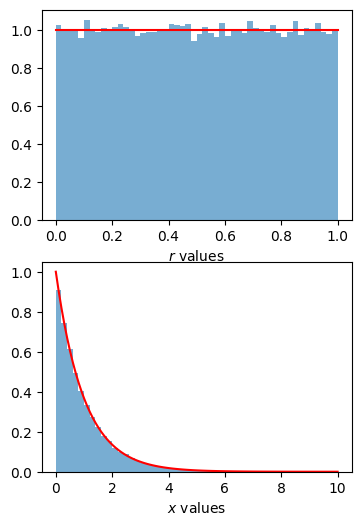

In [5]:
# Example of transformation method: the exponential PDF
r = np.random.uniform(size=100000)

# Our target PDF is f(x) = exp(-x)
# r = F(x) is solved by x(r) = -log(1-r)
x = -np.log(1-r)

fig, ax = plt.subplots(2, 1, figsize=(4, 6))

# Plot r (Uniform)
ax[0].hist(r, bins=50, density=True, alpha=0.6)
ax[0].plot([0, 1], [1, 1], 'r')
ax[0].set_xlabel('$r$ values')

# Plot x (Exponential)
ax[1].hist(x, bins=50, range=(0, 10), density=True, alpha=0.6)
t = np.linspace(0, 10, 100)
ax[1].plot(t, np.exp(-t), 'r')
ax[1].set_xlabel('$x$ values')

plt.show()
#@title { vertical-output: true}

## Example: using scipy.stats classes

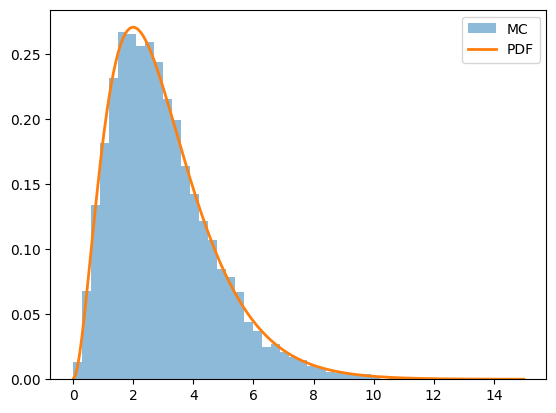

In [6]:
# scipy.stats uses the transformation method to sample generic PDFs
# For a user-given PDF it will numerically calculate the CDF and invert it

# You can define a custsom PDF by sub-classing rv_continuous
from scipy.stats import rv_continuous
class MyPDF(rv_continuous):
    def _pdf(self, x):
        return 0.5 * x**2 * np.exp(-x)   # must be normalized!

# create instance
mypdf = MyPDF(a=0, b=np.inf)

# generate random numbers
samples = mypdf.rvs(size=10000)
plt.hist(samples, bins=50, range=(0,15), density=True, alpha=0.5, label="MC")

# plot the pdf on top
x = np.linspace(0, 15, 200)
plt.plot(x, mypdf.pdf(x), lw=2, label="PDF")

plt.legend()
plt.show()
#@title { vertical-output: true}